In [1]:
# %% [LEADyna: latest main from GitHub]
import subprocess, sys
from pathlib import Path

LEADYNA_DIR = Path.home() / "LEADyna_github"


def git(*args):
    return subprocess.run(["git", "-C", str(LEADYNA_DIR), *args], check=True, capture_output=True, text=True).stdout.strip()


if not (LEADYNA_DIR / ".git").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/ThoHardy/LEADyna.git", str(LEADYNA_DIR)], check=True)
before = git("rev-parse", "HEAD")
git("fetch", "-q", "origin")
git("reset", "-q", "--hard", "origin/main")
src = str(LEADYNA_DIR / "src")
if src not in sys.path:
    sys.path.insert(0, src)
loaded = sys.modules.get("leadyna")
if loaded is not None and (not loaded.__file__.startswith(src) or git("rev-parse", "HEAD") != before):
    raise RuntimeError("An older leadyna is already imported in this kernel: restart it and run this cell first.")
print("LEADyna", git("log", "-1", "--format=%h (%cs) %s"))

LEADyna d56eb59 (2026-11-17) Add leadyna.coupled_viewer: standalone 3-D HTML viewer of fitted coupled stages


In [2]:
# %% [definitions]
import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import subprocess
import sys

LEADYNA_DIR = Path.home() / "LEADyna_github"


def git(*args):
    return subprocess.run(["git", "-C", str(LEADYNA_DIR), *args], check=True, capture_output=True, text=True).stdout.strip()


if not (LEADYNA_DIR / ".git").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/ThoHardy/LEADyna.git", str(LEADYNA_DIR)], check=True)
before = git("rev-parse", "HEAD")
git("fetch", "-q", "origin")
git("reset", "-q", "--hard", "origin/main")
if str(LEADYNA_DIR / "src") not in sys.path:
    sys.path.insert(0, str(LEADYNA_DIR / "src"))
loaded = sys.modules.get("leadyna")
if loaded is not None and (not loaded.__file__.startswith(str(LEADYNA_DIR / "src")) or git("rev-parse", "HEAD") != before):
    raise RuntimeError("An older leadyna is already imported in this kernel: restart it and run this cell first.")
print("LEADyna", git("log", "-1", "--format=%h (%cs) %s"))

from leadyna import CoupledLEAD, coupled_viewer
from leadyna.coupled import evaluate_K, select_K

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDLEAD")
FILTER_TAG = "hp0.3_lp40"
DATA_DIR = repo_root / "Study1" / "epochs" / FILTER_TAG
OUT_DIR = repo_root / "CoupledLEAD" / "Study1" / FILTER_TAG
SNR_DB = {1: -13, 2: -11, 3: -9, 4: -7, 5: -5, 6: -3}      # snr category -> dB (0 = noise only)
TMIN, TMAX, SFREQ = -0.5, None, 100.0
KS = (1, 2, 3)
OPTIONS = dict(k_max=4, n_perm=20, seed=0, n_jobs=None)
LEVEL_COLORS = ["#b7b5ae", "#86b6ef", "#5598e7", "#3987e5", "#256abf", "#1c5cab", "#104281", "#0d366b"]


def load_study1(subject, task):
    ep = mne.read_epochs(DATA_DIR / f"{subject}_{task}-epo.fif", preload=True, verbose=False)
    if ep.baseline is not None:
        warnings.warn(f"{subject} {task}: epochs are baseline-corrected {ep.baseline}; this biases tau.")
    if not np.isclose(ep.info["sfreq"], SFREQ):
        ep = ep.resample(SFREQ, verbose=False)
    ep = ep.pick("eeg").crop(TMIN, TMAX)
    labels = ep.metadata["snr"].astype(int).to_numpy()
    levels = sorted(set(labels.tolist()) - {0})
    cats = np.searchsorted([0] + levels, labels)
    return ep.get_data(), cats, ep.times.copy(), ep.info, [f"{SNR_DB[v]} dB" for v in levels]


def run_subject(subject, task, do_cv=True, overwrite=False):
    path = OUT_DIR / f"{subject}_{task}_coupled.pkl"
    if path.exists() and not overwrite:
        with open(path, "rb") as f:
            return pickle.load(f)
    X, cats, times, info, level_labels = load_study1(subject, task)
    print(f"{subject} {task}: {X.shape[0]} trials x {X.shape[1]} ch x {X.shape[2]} samples, "
          f"trials per category {np.bincount(cats).tolist()}")
    out = dict(subject=subject, task=task, cats=cats, times=times, info=info, level_labels=level_labels,
               fits={K: CoupledLEAD(K=K, **OPTIONS).fit(X, cats, times) for K in KS})
    out["K_perm"] = out["fits"][KS[0]].result_["patterns"]["K_perm"]
    if do_cv:
        out["cv"] = evaluate_K(X, cats, times, KS, **OPTIONS)
        out["sel"] = select_K(out["cv"])
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    with open(path, "wb") as f:
        pickle.dump(out, f)
    return out


def summary_table(out):
    rows = [dict(K=K, stage=s + 1, **{k: v for k, v in row.items() if k != "delta_bic"},
                 dBIC_other=max(row["delta_bic"].values()))
            for K, m in out["fits"].items() for s, row in enumerate(m.summary())]
    return pd.DataFrame(rows).set_index(["K", "stage"])


def plot_fit(out, K):
    res, times, cats = out["fits"][K].result_, out["times"] * 1000, out["cats"]
    pat, casc = res["patterns"], res["cascade"]
    n_lev = int(cats.max()) + 1
    cols = [LEVEL_COLORS[int(round(l * (len(LEVEL_COLORS) - 1) / max(n_lev - 1, 1)))] for l in range(n_lev)]
    fig, axs = plt.subplots(2, K + 1, figsize=(3.6 * (K + 1), 6), squeeze=False)
    ax = axs[0, 0]
    for j, auc in enumerate(pat["auc"]):
        ax.plot(times, auc, lw=1.2, alpha=1 if j < K else 0.4, label=f"step {j + 1}"
                + ("" if np.isnan(pat["thr"][j]) else f" (thr {pat['thr'][j]:.2f})"))
    ax.axhline(0.5, color="0.6", lw=0.8)
    ax.set(xlabel="time (ms)", ylabel="AUC (strongest levels vs rest)", title=f"deflation, K_perm = {pat['K_perm']}")
    ax.legend(fontsize=7, frameon=False)
    for p, i in enumerate(casc["order"]):
        c = casc["comps"][i]
        prm = c["fits"][c["chosen"]]["params"]
        ax = axs[0, p + 1]
        for l in range(n_lev):
            ax.plot(times, res["latents"][cats == l, i].mean(0), color=cols[l], lw=1.4,
                    label="rest" if l == 0 else out["level_labels"][l - 1])
        ax.axhline(0, color="0.6", lw=0.6)
        ax.axvline(pat["t_star"][i] * 1000, color="0.3", lw=0.6, ls=":")
        drive = (f"onset {prm['onset'] * casc['dt'] * 1000:.0f} ms" if p == 0
                 else f"delay {prm['delay'] * casc['dt'] * 1000:.0f} ms, coupling {prm['coupling']:.2f}")
        ax.set(xlabel="time (ms)", ylabel="latent (rest SD)" if p == 0 else None,
               title=f"stage {p + 1}: {c['chosen'].replace('_', ' ')}\ntau {prm['tau'] * casc['dt'] * 1000:.0f} ms, {drive}")
        ax.title.set_fontsize(8)
        mne.viz.plot_topomap(res["A"][:, i], out["info"], axes=axs[1, p + 1], show=False)
    axs[0, -1].legend(fontsize=7, frameon=False, loc="upper left")
    ax = axs[1, 0]
    if "sel" in out:
        ll = out["sel"]["ll"]
        ax.plot(list(ll), np.array(list(ll.values())) - ll[0], "o-", color="k", lw=1)
        ax.set(xlabel="K", ylabel="held-out LL - null", xticks=list(ll),
               title=f"CV: K_elbow {out['sel']['K_elbow']}, K_ll {out['sel']['K_ll']}")
    else:
        ax.axis("off")
    for a in axs[0]:
        a.spines[["top", "right"]].set_visible(False)
    axs[1, 0].spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"{out['subject']} {out['task']} — K = {K}")
    fig.tight_layout()
    return fig


def export_viewer(out, K_default=None):
    K_default = K_default or min(max(out["K_perm"], KS[0]), KS[-1])
    spec = coupled_viewer.viewer_spec(out["fits"], out["info"], level_labels=out["level_labels"],
                                      title=f"Study 1 — {out['subject']} {out['task']}")
    spec["default_config"] = list(sorted(out["fits"])).index(K_default)
    path = OUT_DIR / f"{out['subject']}_{out['task']}_coupled_K{''.join(map(str, KS))}.html"
    path.write_text(coupled_viewer.render_html(spec), encoding="utf-8")
    return path

LEADyna d56eb59 (2026-11-17) Add leadyna.coupled_viewer: standalone 3-D HTML viewer of fitted coupled stages


In [3]:
# %% [fit: one subject, both tasks]
SUBJECTS, TASKS = ["S17"], ["Active", "Passive"]
results = {(s, t): run_subject(s, t) for s in SUBJECTS for t in TASKS}

S17 Passive: 1052 trials x 64 ch x 250 samples, trials per category [155, 146, 152, 151, 145, 149, 154]
fold 1/3  K=1  held-out LL = -379395.9  (null -379625.4)
fold 1/3  K=2  held-out LL = -379258.7  (null -379625.4)
fold 1/3  K=3  held-out LL = -378669.5  (null -379625.4)
fold 2/3  K=1  held-out LL = -383263.6  (null -383526.0)
fold 2/3  K=2  held-out LL = -383090.6  (null -383526.0)
fold 2/3  K=3  held-out LL = -382546.4  (null -383526.0)
fold 3/3  K=1  held-out LL = -378192.6  (null -378460.5)
fold 3/3  K=2  held-out LL = -377976.7  (null -378460.5)
fold 3/3  K=3  held-out LL = -376547.8  (null -378460.5)


S17 Active K_perm = 4 | CV: {'K_perm': 4, 'K_elbow': 3, 'K_ll': 3, 'K_ll_1se': 3}


component           model  parent  t_star_s  tau_s  onset_s  scale_s  \
K stage                                                                         
1 1              0  modulated_gain     NaN      0.40  0.073    0.176    0.063   
2 1              1  modulated_gain     NaN      0.19  0.049    0.090    0.023   
  2              0  modulated_gain     1.0      0.40  0.087      NaN      NaN   
3 1              1  modulated_gain     NaN      0.19  0.050    0.090    0.023   
  2              0  modulated_gain     1.0      0.40  0.088      NaN      NaN   
  3              2          linear     0.0      0.70  0.059      NaN      NaN   

         process_noise  measure_noise   amp1  ...   amp5     g0     g1     g2  \
K stage                                       ...                               
1 1              0.537           0.01  0.020  ...  0.246 -0.000  0.669  0.127   
2 1              0.626           0.01  0.056  ...  0.301  0.036  1.247  0.446   
  2              0.529           0.01    NaN  ...    NaN -0.103  0.032  0.016   
3 1              0.624           0.01  0.055  ...  0.305  0.035  1.168  0.460   
  2              0.527           0.01    NaN  ...    NaN -0.107  0.034  0.016   
  3              0.594           0.01    NaN  ...    NaN    NaN    NaN    NaN   

         threshold  dBIC_other  delay_s  coupling  alpha1  alpha2  
K stage                                                            
1 1          1.126      28.866      NaN       NaN     NaN     NaN  
2 1          0.417     201.880      NaN       NaN     NaN     NaN  
  2         -1.000     247.060    0.073     0.020   0.161     NaN  
3 1          0.342     192.964      NaN       NaN     NaN   0.086  
  2         -1.000     260.746    0.073     0.020   0.155   0.082  
  3            NaN       7.413    0.088     0.026     NaN     NaN  

[6 rows x 23 columns]

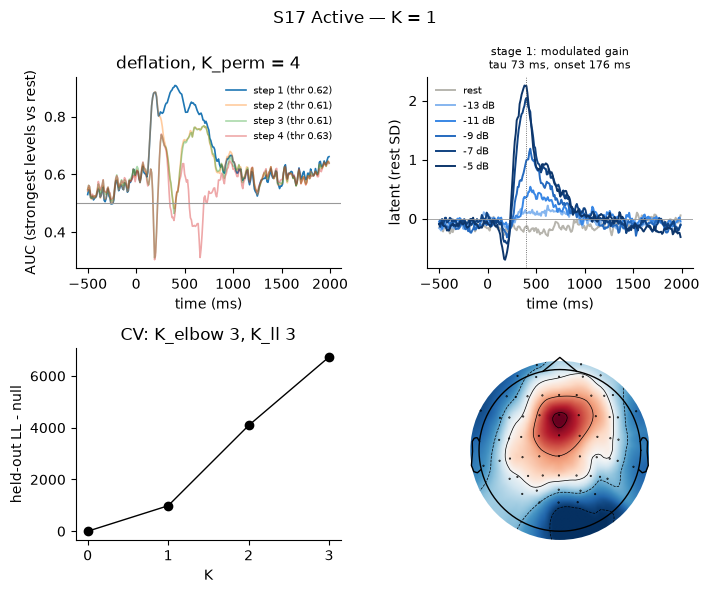

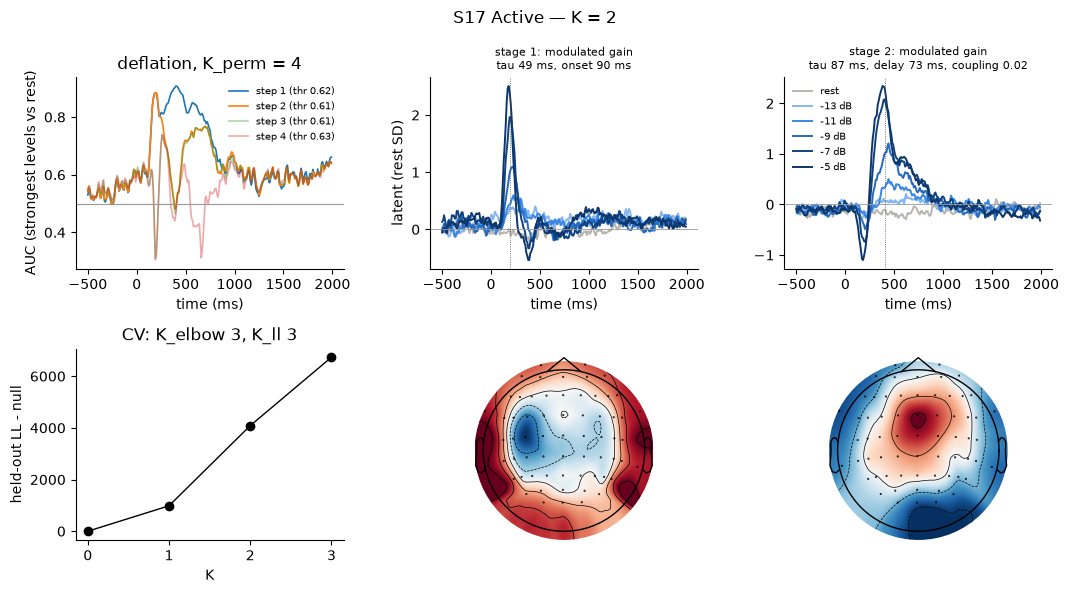

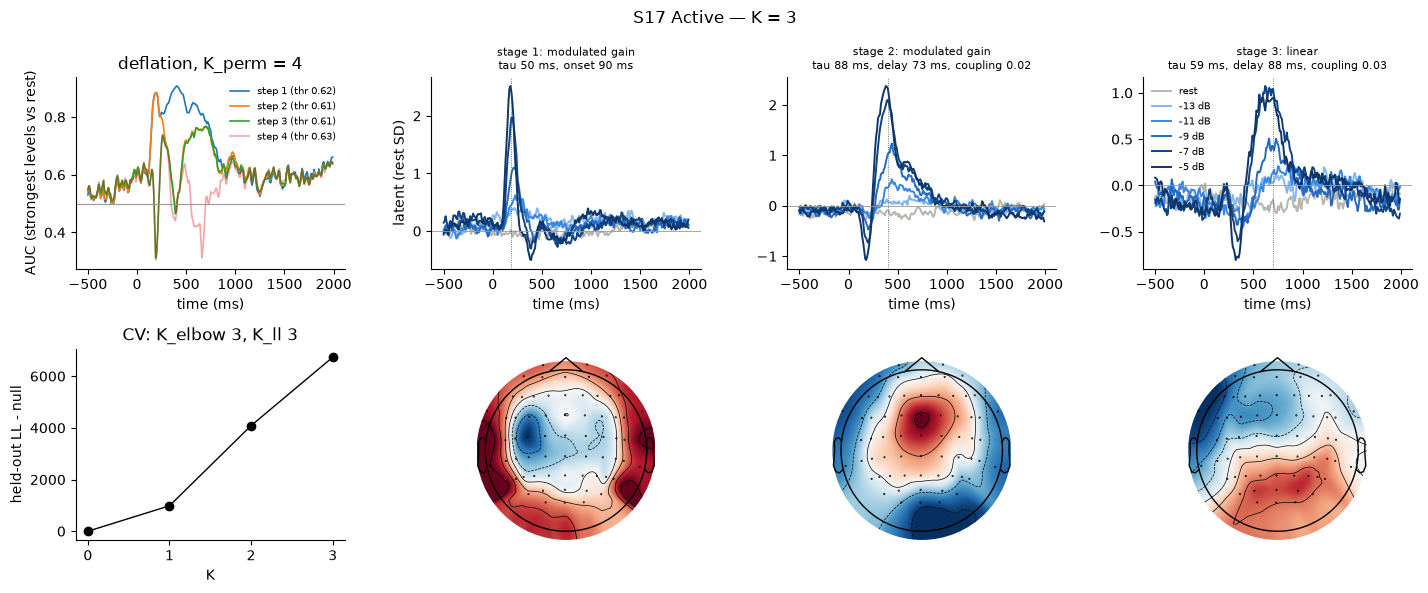

S17 Passive K_perm = 3 | CV: {'K_perm': 3, 'K_elbow': 3, 'K_ll': 3, 'K_ll_1se': 3}


component           model  parent  t_star_s  tau_s  onset_s  scale_s  \
K stage                                                                         
1 1              0  modulated_gain     NaN      0.17  0.060    0.095    0.015   
2 1              0  modulated_gain     NaN      0.17  0.061    0.095    0.015   
  2              1  modulated_gain     0.0      0.35  0.099      NaN      NaN   
3 1              0  modulated_gain     NaN      0.17  0.061    0.095    0.015   
  2              2          linear     0.0      0.24  0.065      NaN      NaN   
  3              1  modulated_gain     2.0      0.35  0.097      NaN      NaN   

         process_noise  measure_noise   amp1  ...   amp6     g0     g1     g2  \
K stage                                       ...                               
1 1              0.502          0.507  0.010  ...  0.411  0.008  0.770  0.092   
2 1              0.497          0.510  0.009  ...  0.422  0.009  0.672  0.145   
  2              0.414          0.452    NaN  ...    NaN  0.444 -0.205 -0.073   
3 1              0.498          0.509  0.008  ...  0.421  0.009  0.686  0.141   
  2              0.518          0.419    NaN  ...    NaN    NaN    NaN    NaN   
  3              0.422          0.437    NaN  ...    NaN  0.170 -0.081  0.025   

         threshold  dBIC_other  alpha1  delay_s  coupling  alpha2  
K stage                                                            
1 1          0.530       9.975     NaN      NaN       NaN     NaN  
2 1          0.483       7.607  -0.066      NaN       NaN     NaN  
  2          3.198     132.877     NaN    0.077     0.023     NaN  
3 1          0.497       9.215  -0.076      NaN       NaN   0.033  
  2            NaN      47.693     NaN    0.040     0.017     NaN  
  3          2.819     118.140     NaN    0.000     0.027  -0.234  

[6 rows x 24 columns]

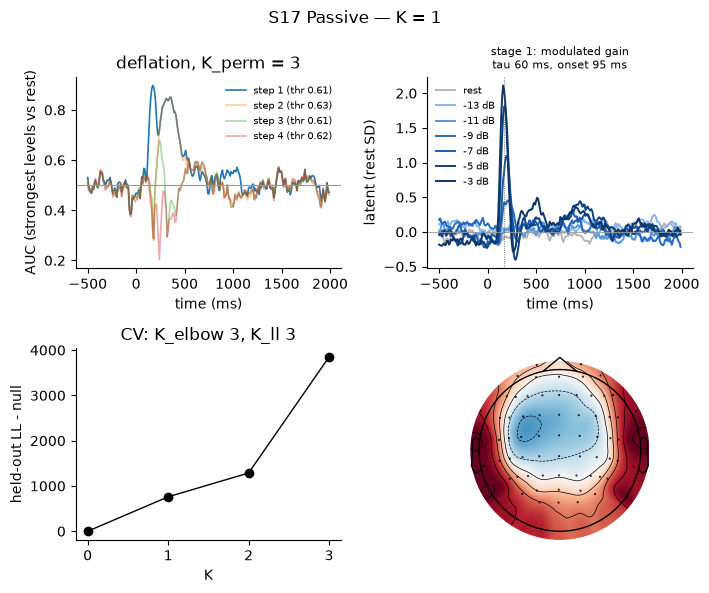

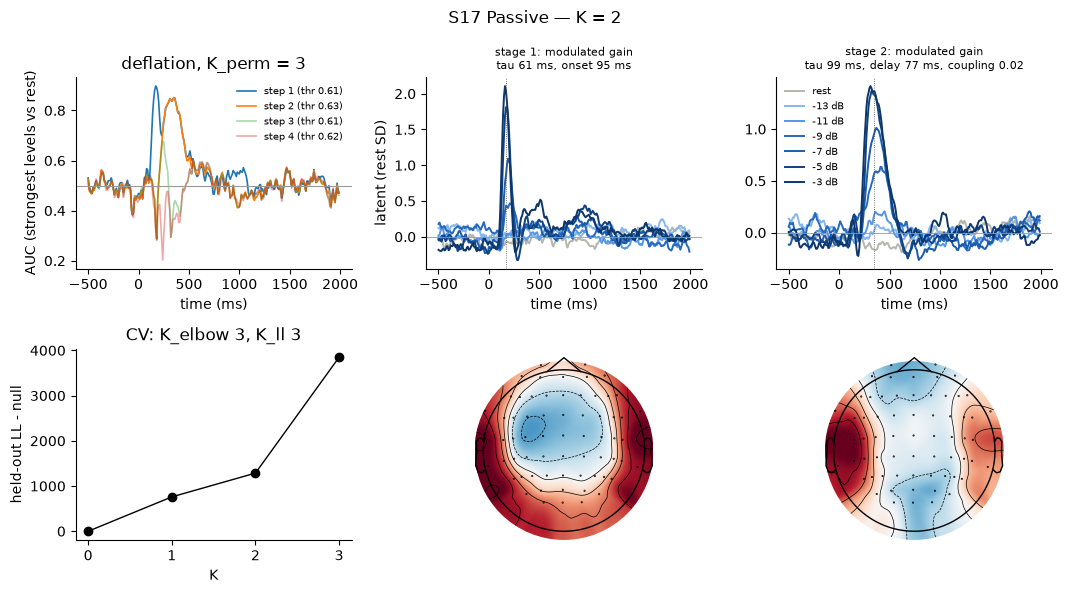

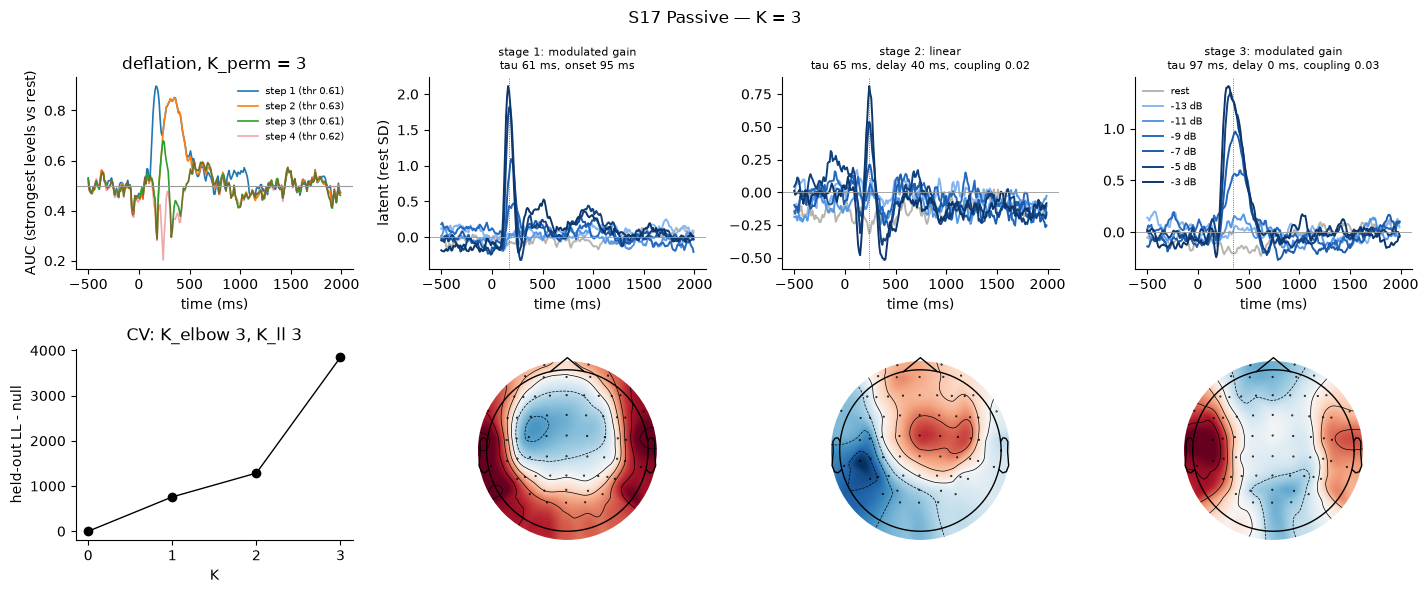

In [4]:
# %% [notebook figures]
for (s, t), out in results.items():
    print(s, t, "K_perm =", out["K_perm"], "| CV:", {k: v for k, v in out.get("sel", {}).items() if k != "ll"})
    display(summary_table(out).round(3))
    for K in KS:
        fig = plot_fit(out, K)
        fig.savefig(OUT_DIR / f"{s}_{t}_coupled_K{K}.png", dpi=150, bbox_inches="tight")
        plt.show()

In [5]:
# %% [3-D viewer]
for out in results.values():
    print(export_viewer(out))   # open the .html in a browser; K is switchable in the page

/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDLEAD/CoupledLEAD/Study1/hp0.3_lp40/S17_Active_coupled_K123.html
/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDLEAD/CoupledLEAD/Study1/hp0.3_lp40/S17_Passive_coupled_K123.html
